In [13]:
import pandas as pd

url = "https://raw.githubusercontent.com/ryanleeallred/datasets/master/heart.csv"
df = pd.read_csv(url)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [6]:
print('---DATA HEALTH---')
df.info()

---DATA HEALTH---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
print('---CLINICAL STATISTICS---')
print(df.describe())

---CLINICAL STATISTICS---
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.366337    0.683168    0.966997  131.623762  246.264026    0.148515   
std      9.082101    0.466011    1.032052   17.538143   51.830751    0.356198   
min     29.000000    0.000000    0.000000   94.000000  126.000000    0.000000   
25%     47.500000    0.000000    0.000000  120.000000  211.000000    0.000000   
50%     55.000000    1.000000    1.000000  130.000000  240.000000    0.000000   
75%     61.000000    1.000000    2.000000  140.000000  274.500000    0.000000   
max     77.000000    1.000000    3.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean     0.528053  149.646865    0.326733    1.039604    1.399340    0.729373   
s

In [8]:
print('\n---PATIENT COHORT----')
print(df['target'].value_counts())


---PATIENT COHORT----
target
1    165
0    138
Name: count, dtype: int64


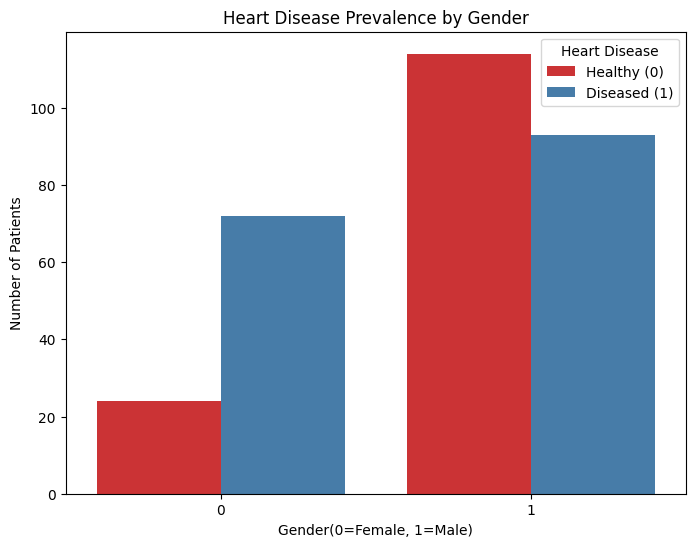

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,6))
sns.countplot(data=df, x='sex', hue='target',palette='Set1')
plt.title('Heart Disease Prevalence by Gender')
plt.xlabel('Gender(0=Female, 1=Male)')
plt.ylabel('Number of Patients')
plt.legend(title='Heart Disease', labels=['Healthy (0)','Diseased (1)'])
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

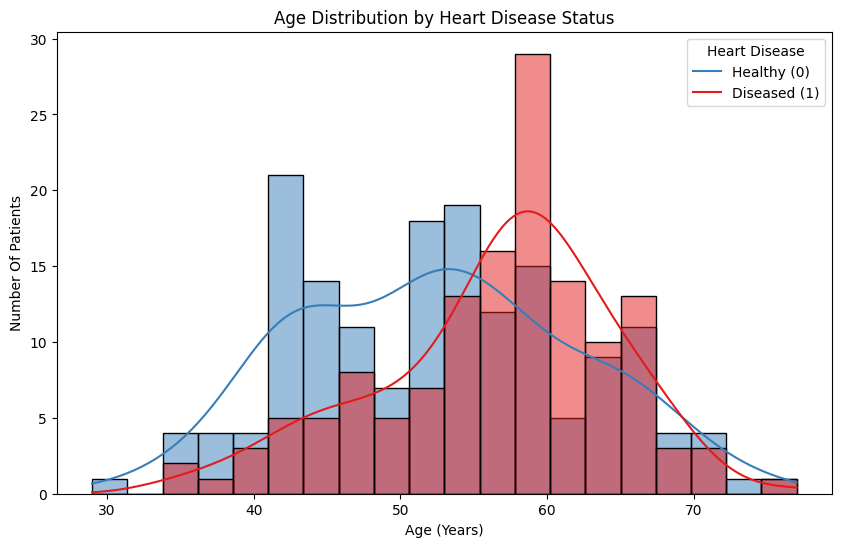

In [15]:
#Realtionship of age to heart disease in this study
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='age', hue='target', kde=True, bins=20, palette='Set1')
plt.title('Age Distribution by Heart Disease Status')
plt.xlabel('Age (Years)')
plt.ylabel('Number Of Patients')
plt.legend(title='Heart Disease', labels=['Healthy (0)', 'Diseased (1)'])
plt.show

The histogram above shows

Below 50 years the blue bars(Healthy) are much taller than the red bars. This means most of the younger patients in this dataset are healthy

**Conclusion:**
The entire distribution of the red curve is shifted to the right (older ages). As age increases, the number of patients with heart disease clearly increases.



**PREVALENCE**

In [18]:
total_pts = len(df)
diseased_pts = len(df[df['target'] ==1])
prevalence = (diseased_pts/total_pts)*100

print(f'Total Patients: {total_pts}')
print(f'Patients with Heart Disease: {diseased_pts}')
print(f'Overal Prevalence: {prevalence:.1f}%')

Total Patients: 303
Patients with Heart Disease: 165
Overal Prevalence: 54.5%


More than half of the patients have heart disease



In [21]:
#Chest pain(Angina) prevalence
# 0 is Typical angina
# 1 is Atypical angina
# 2 is Non-anginal pain
# 3 is Asymptomatic
for cp_type, prevalence in cp_preval.items():
  print(f'Chest Pain Type{cp_type}: {prevalence:.1f}%')

Chest Pain Type0: 27.3%
Chest Pain Type1: 82.0%
Chest Pain Type2: 79.3%
Chest Pain Type3: 69.6%


/tmp/ipykernel_938/137908428.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cp_preval.index, y=cp_preval.values, palette='viridis')


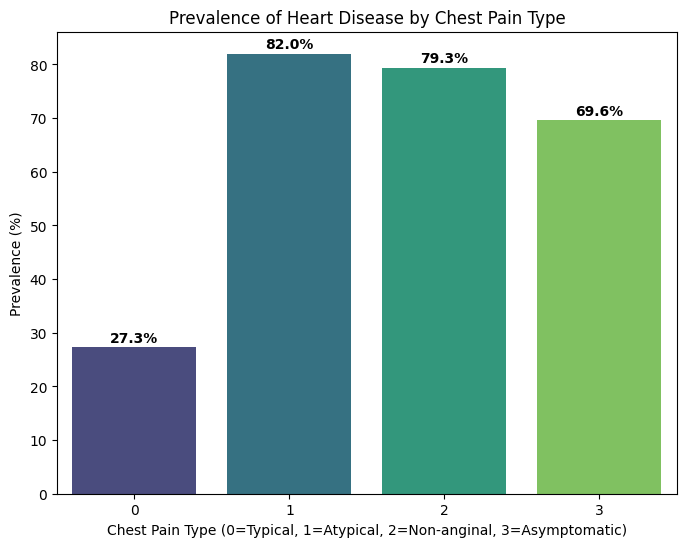

In [22]:
plt.figure(figsize=(8,6))
sns.barplot(x=cp_preval.index, y=cp_preval.values, palette='viridis')
plt.title('Prevalence of Heart Disease by Chest Pain Type')
plt.xlabel('Chest Pain Type (0=Typical, 1=Atypical, 2=Non-anginal, 3=Asymptomatic)')
plt.ylabel('Prevalence (%)')

for i, val in enumerate(cp_preval.values):
  plt.text(i, val+1, f'{val:.1f}%', ha='center', fontweight='bold')
plt.show()

In [25]:
corr_matrix = df.corr()

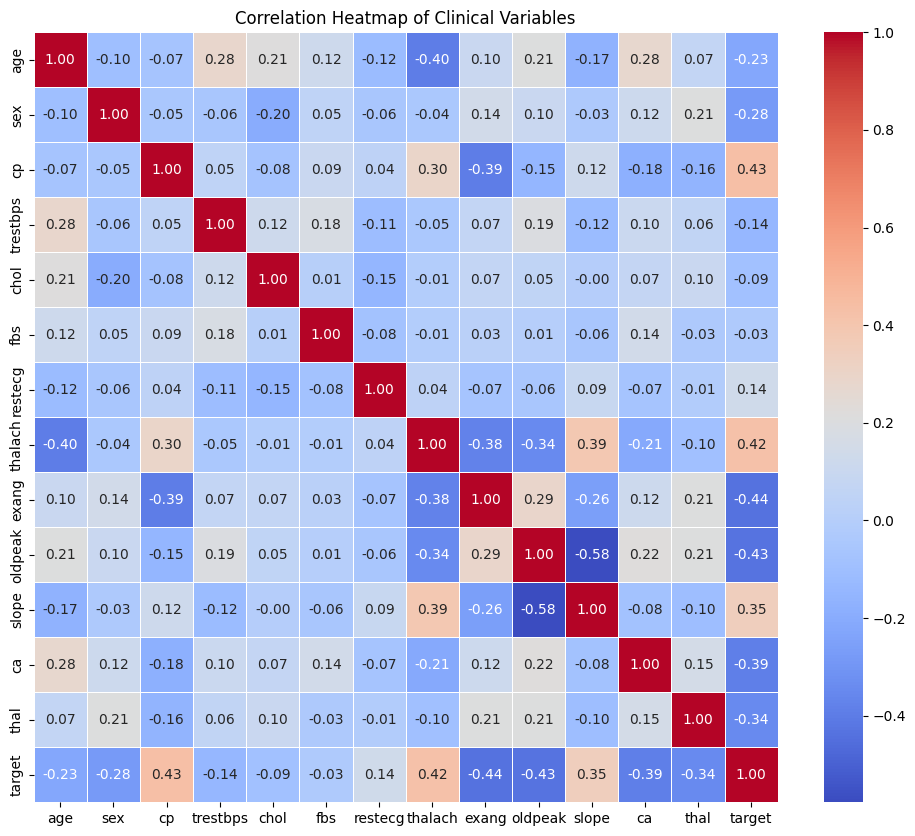

In [30]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Clinical Variables')
plt.show()

**Interpretation**

Red (Positive Correlation): cp (Chest pain type), thalach (Maximum heart rate achieved).

Blue (Negative Correlation): exang (Exercise-induced angina), oldpeak (ST depression), ca (Number of major vessels blocked).

**Clinical Interpretation:** If a patient gets exercise-induced chest pain (exang), has ST depression on their ECG (oldpeak), and has blocked vessels (ca), their correlation with heart disease is strongly negative (remember, 0 is healthy, 1 is diseased, so a negative correlation means the presence of these features strongly predicts disease). Conversely, if they can achieve a high max heart rate (thalach), they are more likely to be healthy.